# Notebook 05 — Fusion Baseline (Simple Concatenation)
Dual-branch CNN with simple feature concatenation. Serves as intermediate baseline between unimodal models and the proposed confidence-weighted fusion.
> **Prerequisites:** Run notebooks 01 and 02 first.

## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Mounted at /content/drive


## 2. Unzip / Download Datasets (Skip if Already Done)

In [2]:
import zipfile, os

# MRI
if not os.path.exists("/content/mri_data/MRI/Training/No Tumor/Tr-no_1.jpg"):
    print("Unzipping MRI...")
    with zipfile.ZipFile("/content/drive/MyDrive/MRI/MRI.zip", 'r') as z:
        z.extractall("/content/mri_data/")
    print("Done!")
else:
    print("MRI already unzipped.")

# CT
if not os.path.exists("/content/ct_tumor/dataset/head ct/no"):
    print("Downloading CT dataset...")
    from google.colab import files
    files.upload()  # upload kaggle.json
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    os.system("cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json")
    os.makedirs("/content/ct_tumor", exist_ok=True)
    os.system("kaggle datasets download -d nipaanjum/head-ct-images-for-classification -p /content/ct_tumor/")
    os.system("unzip /content/ct_tumor/*.zip -d /content/ct_tumor/")
    print("Done!")
else:
    print("CT already downloaded.")

Unzipping MRI...
Done!


Saving kaggle.json to kaggle.json
Done!


## 3. Imports

In [3]:
import numpy as np
import cv2
import random
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

IMG_SIZE   = (224, 224)
BATCH_SIZE = 16
EPOCHS     = 50

print("TensorFlow:", tf.__version__)
print("GPU:", len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow: 2.20.0
GPU: True


## 4. Load Splits from Notebooks 01 and 02

In [4]:
# Load pre-saved splits from NB01 and NB02.
# IMPORTANT: We load train/val/test paths SEPARATELY and pair within each split.
# This preserves the original train/test boundary — no leakage.
mri_data = np.load('/content/drive/MyDrive/MRI/mri_splits.npz',     allow_pickle=True)
ct_data  = np.load('/content/drive/MyDrive/CT_Tumor/ct_splits.npz', allow_pickle=True)

mri_train_paths = mri_data['train_paths']; y_mri_train = mri_data['y_train']
mri_val_paths   = mri_data['val_paths'];   y_mri_val   = mri_data['y_val']
mri_test_paths  = mri_data['test_paths'];  y_mri_test  = mri_data['y_test']

ct_train_paths  = ct_data['train_paths'];  y_ct_train  = ct_data['y_train']
ct_val_paths    = ct_data['val_paths'];    y_ct_val    = ct_data['y_val']
ct_test_paths   = ct_data['test_paths'];   y_ct_test   = ct_data['y_test']

print(f'MRI  — Train:{len(mri_train_paths)} Val:{len(mri_val_paths)} Test:{len(mri_test_paths)}')
print(f'CT   — Train:{len(ct_train_paths)}  Val:{len(ct_val_paths)}  Test:{len(ct_test_paths)}')


MRI  — Train:120 Val:40 Test:40
CT   — Train:120  Val:40  Test:40


## 5. Pair MRI and CT by Class Label Within Each Split


In [5]:
def pair_by_label(paths_a, labels_a, paths_b, labels_b, seed=42):
    """Pair modality A and B images by class label within the same split."""
    import random as _r
    _r.seed(seed)
    a0 = [p for p,l in zip(paths_a, labels_a) if l==0]
    a1 = [p for p,l in zip(paths_a, labels_a) if l==1]
    b0 = [p for p,l in zip(paths_b, labels_b) if l==0]
    b1 = [p for p,l in zip(paths_b, labels_b) if l==1]
    _r.shuffle(a0); _r.shuffle(a1); _r.shuffle(b0); _r.shuffle(b1)
    n0 = min(len(a0), len(b0))
    n1 = min(len(a1), len(b1))
    paired_a = a0[:n0] + a1[:n1]
    paired_b = b0[:n0] + b1[:n1]
    labels   = [0]*n0 + [1]*n1
    return paired_a, paired_b, labels

train_mri_p, train_ct_p, train_labels = pair_by_label(
    mri_train_paths, y_mri_train, ct_train_paths, y_ct_train)
val_mri_p,   val_ct_p,   val_labels   = pair_by_label(
    mri_val_paths,   y_mri_val,   ct_val_paths,   y_ct_val)
test_mri_p,  test_ct_p,  test_labels  = pair_by_label(
    mri_test_paths,  y_mri_test,  ct_test_paths,  y_ct_test)

print(f'Train pairs: {len(train_labels)} | Val pairs: {len(val_labels)} | Test pairs: {len(test_labels)}')


Train pairs: 120 | Val pairs: 40 | Test pairs: 40


## 6. Load Images into Memory

In [6]:
def load_img(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, IMG_SIZE)
    return np.expand_dims(img / 255.0, axis=-1)

print('Loading train...')
X_mri_train = np.array([load_img(p) for p in train_mri_p])
X_ct_train  = np.array([load_img(p) for p in train_ct_p])
y_train     = np.array(train_labels)

print('Loading val...')
X_mri_val   = np.array([load_img(p) for p in val_mri_p])
X_ct_val    = np.array([load_img(p) for p in val_ct_p])
y_val       = np.array(val_labels)

print('Loading test...')
X_mri_test  = np.array([load_img(p) for p in test_mri_p])
X_ct_test   = np.array([load_img(p) for p in test_ct_p])
y_test      = np.array(test_labels)

print(f'Train: {X_mri_train.shape} | Val: {X_mri_val.shape} | Test: {X_mri_test.shape}')


Loading train...
Loading val...
Loading test...
Train: (120, 224, 224, 1) | Val: (40, 224, 224, 1) | Test: (40, 224, 224, 1)


## 7. Splits Already Preserved — No Re-splitting Needed


In [7]:
# Splits are taken directly from NB01/02 via the pair_by_label() function above.
# No re-splitting is performed here, so there is no leakage between train and test.
print(f'Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}')
print(f'Train class dist: {np.bincount(y_train)}')
print(f'Val   class dist: {np.bincount(y_val)}')
print(f'Test  class dist: {np.bincount(y_test)}')


Train: 120 | Val: 40 | Test: 40
Train class dist: [60 60]
Val   class dist: [20 20]
Test  class dist: [20 20]


## 8. Build Fusion Baseline (Simple Concatenation)

In [8]:
def build_fusion_baseline():
    mri_in = layers.Input(shape=(224,224,1), name='MRI_Input')
    x1 = layers.Conv2D(32, (3,3), activation='relu', padding='same')(mri_in)
    x1 = layers.MaxPooling2D()(x1)
    x1 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x1)
    x1 = layers.MaxPooling2D()(x1)
    x1 = layers.GlobalAveragePooling2D()(x1)

    ct_in = layers.Input(shape=(224,224,1), name='CT_Input')
    x2 = layers.Conv2D(32, (3,3), activation='relu', padding='same')(ct_in)
    x2 = layers.MaxPooling2D()(x2)
    x2 = layers.Conv2D(64, (3,3), activation='relu', padding='same')(x2)
    x2 = layers.MaxPooling2D()(x2)
    x2 = layers.GlobalAveragePooling2D()(x2)

    combined = layers.Concatenate()([x1, x2])
    z = layers.Dense(128, activation='relu')(combined)
    z = layers.Dropout(0.4)(z)
    output = layers.Dense(1, activation='sigmoid')(z)

    return models.Model(inputs=[mri_in, ct_in], outputs=output)

fusion_model = build_fusion_baseline()
fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
fusion_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ MRI_Input           │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ CT_Input            │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        320 │ MRI_Input[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 224, 224,  │        320 │ CT_Input[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 112, 112,  │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 56, 56,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_3[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     16,512 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │        129 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 54,273 (212.00 KB)

 Trainable params: 54,273 (212.00 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Train

In [9]:
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = fusion_model.fit(
    [X_mri_train, X_ct_train], y_train,
    validation_data=([X_mri_val, X_ct_val], y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

Epoch 1/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 10s 559ms/step - accuracy: 0.5083 - loss: 0.6937 - val_accuracy: 0.5000 - val_loss: 0.6911
Epoch 2/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5167 - loss: 0.6880 - val_accuracy: 0.5000 - val_loss: 0.6888
Epoch 3/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5083 - loss: 0.6902 - val_accuracy: 0.5000 - val_loss: 0.6868
Epoch 4/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5417 - loss: 0.6846 - val_accuracy: 0.5000 - val_loss: 0.6847
Epoch 5/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.5667 - loss: 0.6816 - val_accuracy: 0.5250 - val_loss: 0.6820
Epoch 6/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6083 - loss: 0.6781 - val_accuracy: 0.5750 - val_loss: 0.6793
Epoch 7/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5917 - loss: 0.6777 - val_accuracy: 0.5250 - val_loss: 0.6770
Epoch 8/50
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6583 - loss: 0.6710 - val_accuracy: 0.5750 - val_loss: 0.674

## 10. Training Curves

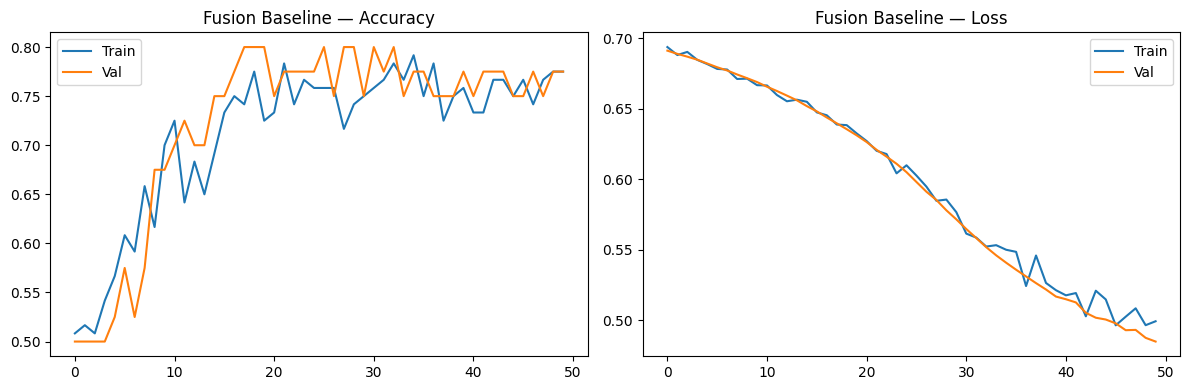

In [10]:
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'],     label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Fusion Baseline — Accuracy')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'],     label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Fusion Baseline — Loss')
plt.legend()
plt.tight_layout()
plt.show()

## 11. Test Set Evaluation

In [11]:
test_probs = fusion_model.predict([X_mri_test, X_ct_test], batch_size=BATCH_SIZE).flatten()
y_pred     = (test_probs > 0.5).astype(int)

print("--- FUSION BASELINE: TEST SET RESULTS ---")
print(classification_report(y_test, y_pred, target_names=['Healthy','Tumor']))
print(f"ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 245ms/step
--- FUSION BASELINE: TEST SET RESULTS ---
              precision    recall  f1-score   support

     Healthy       0.78      0.70      0.74        20
       Tumor       0.73      0.80      0.76        20

    accuracy                           0.75        40
   macro avg       0.75      0.75      0.75        40
weighted avg       0.75      0.75      0.75        40

ROC-AUC: 0.8250


## 12. Confusion Matrix

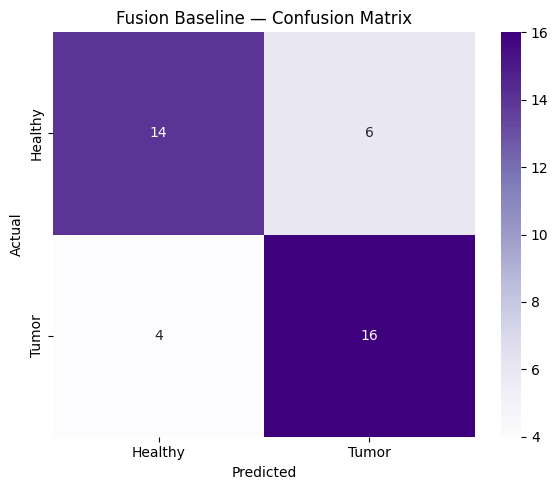

In [12]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Healthy','Tumor'], yticklabels=['Healthy','Tumor'])
plt.title('Fusion Baseline — Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

## 13. Save Model

In [13]:
fusion_model.save("/content/drive/MyDrive/CT_Tumor/fusion_baseline.keras")
print("Model saved!")

Model saved!
